# CYTAP tutorial

CYTAP scores every cell of a scRNA-seq dataset for its response to 90 cytokines and finds the cytokine
responses that differ between conditions.

1. **Paired design**: IFN-β-stimulated PBMCs (Kang et al. 2018), where every donor has control and
   stimulated cells. Runs right after installation.
2. **Unpaired design**: COVID-19 severity in COMBAT (COMBAT Consortium 2022), healthy volunteers vs patients.
   Needs a data download (section 4).

The pretrained model and the example data are downloaded automatically the first time they are used.

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc

import cytap

## 1. Input

CYTAP takes an AnnData with
- `obsm['X_state']`: the State SE-600M embedding of each cell,
- `obs` columns for the condition (including a control label), the donor and the cell type.

To embed your own data, run [State](https://github.com/ArcInstitute/state) on log-normalized counts:

```bash
state emb transform --model-folder SE-600M --input query_normalized.h5ad --output query_state_emb.h5ad
```

The IFN-β example is already embedded: `stim` (`ctrl` / `stim`), `ind` (donor), `cell` (cell type).

In [2]:
adata = cytap.load_example("ifnb")
adata.obs.groupby(["ind", "stim"], observed=True).size().unstack()

stim,ctrl,stim
ind,,
101,858,1128
107,517,511
1015,2738,2295
1016,1723,1578
1039,461,629
1244,1879,1438
1256,2108,1984
1488,2031,2488


## 2. Prediction

`design` tells CYTAP where the control cells come from:
- `"paired"`: every donor has its own control cells (as here);
- `"unpaired"`: control cells come from other donors, e.g. healthy volunteers vs patients (sections 4–5).

In [3]:
model = cytap.load_model()
out = cytap.predict(adata, model, design="paired", control_key="stim", control_label="ctrl",
                    donor_key="ind", celltype_key="cell")
out

/tmp/ipykernel_59958/3597677697.py:2: UserWarning: 6 of 24366 cells were not scored (6 missing donor/cell-type label); the returned AnnData has 24360 cells. Assign it to a new name to keep the input (out = cytap.predict(adata, ...)); uns['cytap']['dropped_cells'] has the counts.
  out = cytap.predict(adata, model, design="paired", control_key="stim", control_label="ctrl",


AnnData object with n_obs × n_vars = 24360 × 0
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'ind', 'stim', 'cluster', 'cell', 'multiplets'
    uns: 'pred_classes', 'cytap'
    obsm: 'X_state', 'pred_probs', 'pred_logits'

`predict` returns a new AnnData with
- `obsm['pred_probs']`: probability of each cytokine (cells × 90),
- `obsm['pred_logits']`: log(p / (1 − p)), used for the comparisons below.

Cells that cannot be scored (e.g. a cell type without control cells) are left out with a warning.
`cytap.stats.logits` gives the logits as a table:

In [4]:
cytap.stats.logits(out).iloc[:5, :6]

,4-1BBL,ADSF,APRIL,BAFF,C3a,C5a
AAACATACATTTCC-1,-1.636522,-4.494725,-5.527520,-4.038334,-2.691585,-5.587636
AAACATACCAGAAA-1,-3.493646,-6.453885,-8.258704,-3.588572,-3.746559,-4.989223
AAACATACCATGCA-1,-3.467273,-5.794775,-5.602066,-5.365921,-4.036445,-6.464959
AAACATACCTCGCT-1,-2.849747,-6.408232,-9.419692,-8.777858,-4.154853,-6.374517
AAACATACCTGGTA-1,-2.431709,-5.919129,-6.560954,-6.157227,-1.421162,-5.666379


## 3. Comparing conditions

Donors are the replicates: the median logit per donor is compared between conditions (one-sided paired
t-test, stim > ctrl; FDR over the 90 cytokines). `delta_logit` is the effect size.

In [5]:
res = cytap.stats.compare_conditions(out, condition_key="stim", ctrl="ctrl", stim="stim", donor_key="ind")
res[res["fdr"] < 0.05].sort_values("delta_logit", ascending=False).head(10)

,cytokine,mean_logit_stim,mean_logit_ctrl,delta_logit,log2fc_prob,n_stim,n_ctrl,pval,fdr
28,IFN-omega,-3.842218,-11.709484,7.867266,11.405295,8,8,4.736825e-10,8.526285e-09
22,IFN-beta,-1.851124,-9.250696,7.399572,10.506766,8,8,8.753025e-10,1.312954e-08
21,IFN-alpha1,-3.858981,-7.980901,4.121920,5.917710,8,8,4.003793e-11,2.696649e-09
47,IL-2,-3.429007,-6.705431,3.276424,4.692603,8,8,2.687229e-10,6.046266e-09
36,IL-15,-3.274503,-6.175524,2.901021,4.145288,8,8,5.992554e-11,2.696649e-09
66,IL-7,-6.133575,-8.704931,2.571356,3.726218,8,8,4.843613e-09,5.449065e-08
24,IFN-gamma,-3.825761,-6.224537,2.398776,3.437409,8,8,1.165504e-10,3.496512e-09
19,GM-CSF,-6.175550,-8.210789,2.035239,2.943209,8,8,2.413609e-09,3.103211e-08
25,IFN-lambda1,-7.114844,-8.677127,1.562283,2.272988,8,8,1.183482e-07,1.183482e-06
40,IL-17C,-6.243438,-7.650683,1.407246,2.049575,8,8,2.177238e-07,1.959515e-06


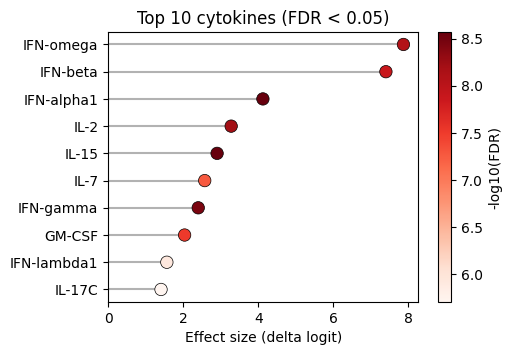

In [6]:
cytap.plotting.lollipop(res)   # top 10 cytokines with FDR < 0.05
plt.show()

One cytokine across cell types: change of the median logit (stim − ctrl), one point per donor.

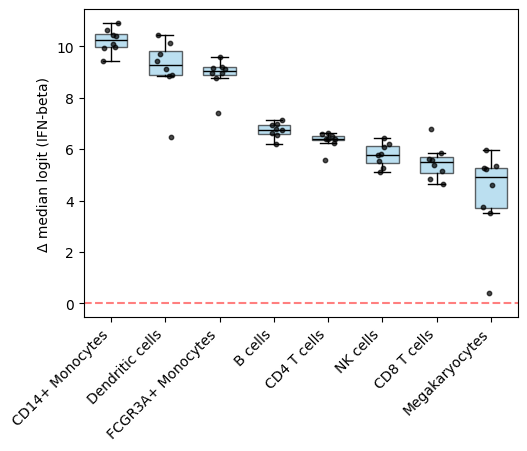

In [7]:
cytap.plotting.delta(out, "IFN-beta", condition_key="stim", baseline="ctrl", targets="stim",
                     donor_key="ind", celltype_key="cell")
plt.show()

The IFN-β logit on a UMAP of the State embedding:

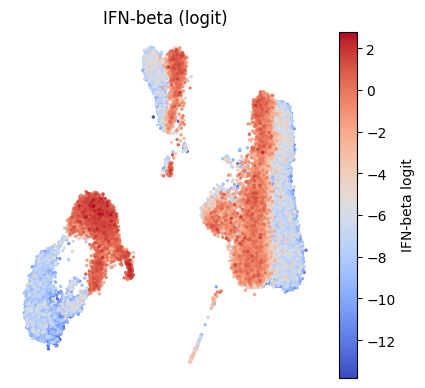

In [8]:
sc.pp.neighbors(out, use_rep="X_state")
sc.tl.umap(out)
cytap.plotting.embedding(out, "IFN-beta", basis="X_umap")
plt.show()

## 4. Unpaired data: COVID-19 severity (COMBAT)

Download `query_slim.tar` from the CYTAP Zenodo record
([10.5281/zenodo.XXXXXXX](https://doi.org/10.5281/zenodo.XXXXXXX)) and extract the COMBAT file
(435,837 cells; about 4 GB, so prediction needs a machine with ample memory):

```bash
wget https://zenodo.org/records/XXXXXXX/files/query_slim.tar
tar -xf query_slim.tar data/query_slim/combat_state_emb.h5ad
```

Healthy volunteers (HV) and patients are different people, so patients have no control cells of their own:
`design="unpaired"`. By default the control cells of each cell type are pooled over all HV donors.

In [9]:
ORDER = ["HV", "COVID_MILD", "COVID_SEV", "COVID_CRIT"]
combat = ad.read_h5ad("data/query_slim/combat_state_emb.h5ad")
combat.obs.groupby("Source", observed=True)["donor_id"].nunique()

Source
COVID_CRIT    18
COVID_MILD    17
COVID_SEV     28
HV            10
Name: donor_id, dtype: int64

In [10]:
out_pooled = cytap.predict(combat, model, design="unpaired", control_key="Source", control_label="HV",
                           celltype_key="major_subset")

Cytokines whose donor-level logit increases with severity (Spearman correlation over
HV < mild < severe < critical):

In [11]:
trend = cytap.stats.severity_trend(out_pooled, condition_key="Source", order=ORDER, donor_key="donor_id")
trend[trend["fdr"] < 0.05].sort_values("rho", ascending=False).head(10)

,cytokine,rho,slope,pval,fdr,n_donors
57,IL-32-beta,0.705002,0.488413,3.354007e-12,3.018607e-10,73
49,IL-21,0.677855,0.497983,4.482349e-11,2.017057e-09,73
47,IL-2,0.461211,0.510827,4.015691e-05,7.228243e-04,73
5,C5a,0.391099,0.176188,6.233721e-04,7.012936e-03,73
31,IL-1-beta,0.360014,0.247621,1.757075e-03,1.522205e-02,73
67,IL-8,0.358207,0.125095,1.860472e-03,1.522205e-02,73
65,IL-6,0.330172,0.221307,4.334036e-03,3.000487e-02,73
29,IGF-1,0.320310,0.251185,5.732726e-03,3.439636e-02,73
41,IL-17D,0.310384,0.289588,7.528732e-03,4.234912e-02,73
40,IL-17C,0.300474,0.325503,9.796562e-03,4.898281e-02,73


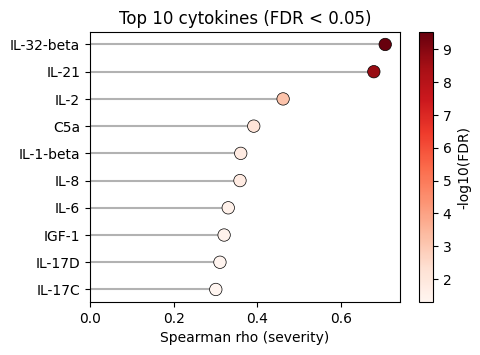

In [12]:
cytap.plotting.lollipop(trend, x="rho")
plt.show()

Two groups, e.g. critical vs HV (`paired=False`: Welch's t-test over donors):

In [13]:
crit = cytap.stats.compare_conditions(out_pooled, condition_key="Source", ctrl="HV", stim="COVID_CRIT",
                                     donor_key="donor_id", paired=False)
crit[crit["fdr"] < 0.05].sort_values("delta_logit", ascending=False).head(10)

,cytokine,mean_logit_stim,mean_logit_ctrl,delta_logit,log2fc_prob,n_stim,n_ctrl,pval,fdr
47,IL-2,-7.793172,-9.650848,1.857676,2.966518,18,10,1.137037e-07,3.411111e-06
28,IFN-omega,-11.602435,-13.320585,1.718150,4.251675,18,10,2.882090e-04,4.323135e-03
49,IL-21,-3.380604,-4.992238,1.611634,2.376672,18,10,8.345111e-10,5.314793e-08
22,IFN-beta,-11.720958,-13.240812,1.519855,4.034044,18,10,1.392612e-03,1.402035e-02
57,IL-32-beta,-6.254741,-7.772388,1.517648,2.239454,18,10,1.181065e-09,5.314793e-08
24,IFN-gamma,-9.346981,-10.713717,1.366735,1.918314,18,10,1.094699e-03,1.402035e-02
40,IL-17C,-9.934153,-11.162792,1.228640,2.069855,18,10,2.231203e-04,4.016166e-03
21,IFN-alpha1,-12.168241,-13.349095,1.180855,3.627865,18,10,1.053650e-02,4.122980e-02
74,M-CSF,-8.099363,-9.148718,1.049355,1.016304,18,10,1.103543e-02,4.138288e-02
41,IL-17D,-10.445538,-11.368242,0.922705,1.616920,18,10,4.430954e-03,3.067583e-02


## 5. Unpaired data: counterfactual controls (CellOT)

With `reference="counterfactual"`, each patient gets a control reference made from their own cells: CellOT
maps (one per condition, condition → HV) predict how these cells would look in the control state.

Here the maps trained for the paper are used (`"combat_cellot"`). For your own data, leave out
`counterfactual=` and `predict` trains the maps itself (a GPU is recommended); add
`cellot_kwargs={"save": "maps.pt"}` to keep them and `CellOT.load("maps.pt")` to reuse them.

In [14]:
from cytap.counterfactual import CellOT

cot = CellOT.load("combat_cellot")
out_cf = cytap.predict(combat, model, design="unpaired", reference="counterfactual", counterfactual=cot,
                       control_key="Source", control_label="HV", donor_key="donor_id",
                       celltype_key="major_subset")
trend_cf = cytap.stats.severity_trend(out_cf, condition_key="Source", order=ORDER, donor_key="donor_id")
trend_cf[trend_cf["fdr"] < 0.05].sort_values("rho", ascending=False).head(10)

,cytokine,rho,slope,pval,fdr,n_donors
57,IL-32-beta,0.729551,0.409201,2.467844e-13,1.110530e-11,73
49,IL-21,0.698207,0.375795,6.592897e-12,1.977869e-10,73
31,IL-1-beta,0.566474,0.316643,1.752248e-07,1.971279e-06,73
29,IGF-1,0.524317,0.238353,1.925856e-06,1.733271e-05,73
65,IL-6,0.513633,0.252498,3.363616e-06,2.522712e-05,73
44,IL-18,0.491327,0.188629,1.015679e-05,7.031621e-05,73
67,IL-8,0.413889,0.099319,2.727427e-04,1.227342e-03,73
41,IL-17D,0.397410,0.270619,4.987512e-04,1.870317e-03,73
78,PRL,0.347942,0.122085,2.558310e-03,8.223139e-03,73
47,IL-2,0.345617,0.280964,2.745660e-03,8.521015e-03,73


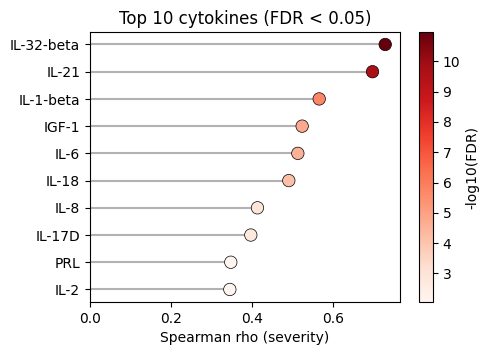

In [15]:
cytap.plotting.lollipop(trend_cf, x="rho")
plt.show()

## 6. Command line

The same predictions without Python (`cytap predict --help` lists all options):

```bash
# paired
cytap predict query.h5ad out.h5ad --design paired \
    --control-key stim --control-label ctrl --donor-key ind --celltype-key cell
# unpaired, pooled controls
cytap predict query.h5ad out.h5ad --design unpaired \
    --control-key Source --control-label HV --celltype-key major_subset
# unpaired, counterfactual controls (maps trained if --counterfactual is omitted)
cytap predict query.h5ad out.h5ad --design unpaired --reference counterfactual --counterfactual maps.pt \
    --control-key Source --control-label HV --donor-key donor_id --celltype-key major_subset
```